# PyTorch U-Net training on Google Colab GPU

This notebook runs the repository's existing PyTorch scripts; it does not redefine the model or preprocessing. In Colab, select **Runtime → Change runtime type → T4 GPU** (or another CUDA GPU) before running. The GPU smoke test must pass before the full-training cell is enabled by execution order.

Copy the project folder to Google Drive, including `python/`, `data/`, and (if available) `model_output/smoke_test/patient_split.json`. Set `PROJECT_ROOT` below to that folder. Model artifacts and logs are written to a timestamped Drive folder. If the dataset is not present there, the notebook can download it using Colab Secrets named `KAGGLE_USERNAME` and `KAGGLE_KEY`; credentials are never displayed or saved in the project.

**Protocol:** deterministic patient split seed 42; original 1-channel 2D U-Net; 256×256 inputs; Adam 1e-4; BCE + soft Dice; batch 8; maximum 100 epochs; validation Dice selects the checkpoint; early stopping patience 12. The unseen test set is excluded from training and selection. Its one-time final evaluation is protected by a run-specific lock. ONNX parity compares the same held-out inputs but does not tune metrics or thresholds.

No GPU training, test metrics, or ONNX results are claimed until the corresponding cells complete successfully.

In [1]:
from google.colab import drive
from pathlib import Path
import os

drive.mount('/content/drive')

# Change this to the project folder you copied to Google Drive.
PROJECT_ROOT = Path('/content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB')
if not (PROJECT_ROOT / 'python' / 'train_pytorch.py').is_file():
    raise FileNotFoundError(f'Update PROJECT_ROOT; trainer not found under {PROJECT_ROOT}')
print('Project source found:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project source found: /content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Keep Colab's preinstalled CUDA-enabled PyTorch; install only the other project dependencies.
import subprocess
import sys
import torch

subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', 'numpy>=1.26,<3', 'Pillow>=10', 'matplotlib>=3.8'],
    check=True,
)
import numpy as np
from PIL import Image

if not torch.cuda.is_available():
    raise RuntimeError('CUDA is unavailable. Select a GPU runtime and rerun before continuing.')
print({'torch': torch.__version__, 'cuda': torch.version.cuda, 'gpu': torch.cuda.get_device_name(0)})

{'torch': '2.11.0+cu130', 'cuda': '13.0', 'gpu': 'Tesla T4'}


In [4]:
from datetime import datetime
import json
import sys

PYTHON_DIR = PROJECT_ROOT / 'python'
sys.path.insert(0, str(PYTHON_DIR))
from pytorch_pipeline import (
    FLAIR_CHANNEL_INDEX, IMAGE_SIZE, SEED, LGGDataset, UNet,
    bce_dice_loss, collect_pairs, load_flair_and_mask,
    make_split_manifest, model_configuration, validate_pairs,
)

assert IMAGE_SIZE == 256 and SEED == 42 and FLAIR_CHANNEL_INDEX == 1
expected_model = {
    'architecture': 'original_2d_unet',
    'input_channels': 1,
    'encoder_channels': [64, 128, 256, 512],
    'bottleneck_channels': 1024,
    'decoder_channels': [512, 256, 128, 64],
    'output_channels': 1,
    'output_activation': 'sigmoid',
    'input_shape_nchw': [1, 1, 256, 256],
    'output_shape_nchw': [1, 1, 256, 256],
    'probability_threshold': 0.5,
}
assert model_configuration() == expected_model, model_configuration()
assert torch.optim.Adam is not None and callable(bce_dice_loss)

RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S')
RUN_DIR = PROJECT_ROOT / 'model_output' / 'colab_runs' / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)
DATA_DIR = PROJECT_ROOT / 'data' / 'lgg-mri-segmentation' / 'kaggle_3m'
gpu_properties = torch.cuda.get_device_properties(0)
environment = {
    'python_version': sys.version,
    'torch_version': torch.__version__,
    'cuda_version': torch.version.cuda,
    'cuda_available': torch.cuda.is_available(),
    'gpu_name': torch.cuda.get_device_name(0),
    'gpu_total_memory_bytes': gpu_properties.total_memory,
    'gpu_multiprocessor_count': gpu_properties.multi_processor_count,
}
(RUN_DIR / 'colab_environment.json').write_text(json.dumps(environment, indent=2), encoding='utf-8')
print({'run_dir': str(RUN_DIR), 'configured_batch_size': 8, 'max_epochs': 100, 'patience': 12, **environment})

{'run_dir': '/content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/model_output/colab_runs/20261101_205443', 'configured_batch_size': 8, 'max_epochs': 100, 'patience': 12, 'python_version': '3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]', 'torch_version': '2.11.0+cu130', 'cuda_version': '13.0', 'cuda_available': True, 'gpu_name': 'Tesla T4', 'gpu_total_memory_bytes': 15637086208, 'gpu_multiprocessor_count': 40}


In [7]:
# ============================================
# Download LGG MRI Dataset using Kaggle API
# ============================================

from google.colab import files
import subprocess
import sys
import json
from pathlib import Path

# Step 1: Upload kaggle.json
print("Upload your kaggle.json")

uploaded = files.upload()

if 'kaggle.json' not in uploaded:
    raise FileNotFoundError("kaggle.json not uploaded")

# Step 2: Configure Kaggle API
kaggle_config = Path('/root/.kaggle')
kaggle_config.mkdir(parents=True, exist_ok=True)

config_file = kaggle_config / 'kaggle.json'
config_file.write_bytes(uploaded['kaggle.json'])
config_file.chmod(0o600)

# Step 3: Install Kaggle
subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', 'kaggle'],
    check=True
)

# Step 4: Download dataset
DOWNLOAD_DIR = Path('/content/kaggle_download')
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

print("Downloading LGG MRI dataset...")

subprocess.run(
    [
        'kaggle',
        'datasets',
        'download',
        '-d', 'mateuszbuda/lgg-mri-segmentation',
        '-p', str(DOWNLOAD_DIR),
        '--unzip'
    ],
    check=True
)

# Step 5: Locate dataset
DATA_DIR = DOWNLOAD_DIR / 'kaggle_3m'

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}"
    )

print("Dataset downloaded successfully!")
print("DATA_DIR:", DATA_DIR)

Upload your kaggle.json


Saving kaggle.json to kaggle.json
Dataset downloaded successfully!
DATA_DIR: /content/kaggle_download/kaggle_3m


In [8]:
# Locate README
readme_candidates = [
    DOWNLOAD_DIR / 'README.md',
    PROJECT_ROOT / 'data' / 'lgg-mri-segmentation' / 'kaggle_3m' / 'README.md',
    PYTHON_DIR / 'README_PYTORCH.md',
]

dataset_readme = next(
    (p for p in readme_candidates if p.is_file()),
    None
)

if dataset_readme is None:
    raise FileNotFoundError("MRI modality README not found")

readme_text = dataset_readme.read_text(
    encoding='utf-8'
).lower()

if not all(
    term in readme_text
    for term in ['flair', 'pre-contrast', 'post-contrast']
):
    raise ValueError("MRI channel documentation is incomplete")

# Validate dataset
pairs = collect_pairs(DATA_DIR)

if not pairs:
    raise RuntimeError("No image-mask pairs found")

dataset_report = validate_pairs(pairs)

sample_flair, sample_mask = load_flair_and_mask(
    pairs[0],
    image_size=IMAGE_SIZE
)

assert sample_flair.shape == (256, 256)
assert sample_mask.shape == (256, 256)

assert sample_flair.dtype == np.float32
assert sample_mask.dtype == np.float32

assert set(np.unique(sample_mask)).issubset({0.0, 1.0})

print({
    'dataset_dir': str(DATA_DIR),
    'readme': str(dataset_readme),
    **dataset_report,
    'flair_shape': sample_flair.shape,
    'mask_shape': sample_mask.shape,
})

{'dataset_dir': '/content/kaggle_download/kaggle_3m', 'readme': '/content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/data/lgg-mri-segmentation/kaggle_3m/README.md', 'pair_count': 3929, 'patient_count': 110, 'image_shapes': [[256, 256, 3]], 'mask_shapes': [[256, 256]], 'mask_values': [0, 255], 'flair_shape': (256, 256), 'mask_shape': (256, 256)}


In [9]:
# Confirm deterministic split against the preserved local smoke manifest when available.
split_manifest = make_split_manifest(pairs, seed=SEED)
assert all(not overlap for overlap in split_manifest['overlap_check'].values())
assert [split_manifest['splits'][name]['patient_count'] for name in ('train', 'validation', 'test')] == [77, 17, 16]
assert [split_manifest['splits'][name]['image_count'] for name in ('train', 'validation', 'test')] == [2719, 641, 569]
reference_split_path = PROJECT_ROOT / 'model_output' / 'smoke_test' / 'patient_split.json'
if reference_split_path.is_file():
    reference = json.loads(reference_split_path.read_text(encoding='utf-8'))
    if reference != split_manifest:
        raise ValueError('Colab split differs from the saved local seed-42 split; stopping rather than changing the test cohort.')
    print('Exact split matches local smoke manifest.')
else:
    print('No prior local manifest found; deterministic seed-42 split is verified against expected counts.')
print({name: {'patients': item['patient_count'], 'slices': item['image_count']}
       for name, item in split_manifest['splits'].items()})

Exact split matches local smoke manifest.
{'train': {'patients': 77, 'slices': 2719}, 'validation': {'patients': 17, 'slices': 641}, 'test': {'patients': 16, 'slices': 569}}


## GPU smoke test — required gate

Runs the existing `train_pytorch.py --smoke-test` path: two epochs, batch size 1, one positive training slice and one positive validation slice. It still uses the full required U-Net and must execute on CUDA. This is a separate GPU smoke test, not the previously completed CPU smoke run. Do not continue if this cell fails.

In [10]:
import gc
import subprocess

def run_logged(command, log_path):
    with log_path.open('w', encoding='utf-8') as log:
        completed = subprocess.run(command, cwd=PROJECT_ROOT, stdout=log, stderr=subprocess.STDOUT, text=True)
    if completed.returncode:
        tail = log_path.read_text(encoding='utf-8', errors='replace').splitlines()[-80:]
        raise RuntimeError(f'Command failed ({completed.returncode}); see {log_path}:\n' + '\n'.join(tail))
    print('\n'.join(log_path.read_text(encoding='utf-8', errors='replace').splitlines()[-24:]))

# Explicitly verify a real 256x256 forward/backward batch is placed on CUDA.
gpu_model = UNet(use_checkpointing=False).to('cuda')
gpu_images = torch.from_numpy(sample_flair[None, None, ...]).to('cuda')
gpu_masks = torch.from_numpy(sample_mask[None, None, ...]).to('cuda')
gpu_optimizer = torch.optim.Adam(gpu_model.parameters(), lr=1e-4)
gpu_optimizer.zero_grad(set_to_none=True)
gpu_probabilities = gpu_model(gpu_images)
gpu_loss = bce_dice_loss(gpu_probabilities, gpu_masks)
gpu_loss.backward()
gpu_optimizer.step()
assert tuple(gpu_images.shape) == (1, 1, 256, 256)
assert tuple(gpu_probabilities.shape) == (1, 1, 256, 256)
assert gpu_images.device.type == gpu_masks.device.type == gpu_probabilities.device.type == 'cuda'
assert torch.isfinite(gpu_loss).item()
print({'input_shape': tuple(gpu_images.shape), 'input_device': str(gpu_images.device),
       'output_shape': tuple(gpu_probabilities.shape), 'output_device': str(gpu_probabilities.device),
       'one_step_loss': float(gpu_loss.detach().cpu())})
del gpu_model, gpu_images, gpu_masks, gpu_optimizer, gpu_probabilities, gpu_loss
gc.collect()
torch.cuda.empty_cache()

smoke_command = [
    sys.executable, str(PYTHON_DIR / 'train_pytorch.py'),
    '--data-dir', str(DATA_DIR), '--output-dir', str(RUN_DIR),
    '--seed', str(SEED), '--image-size', '256', '--cpu-threads', '2', '--smoke-test',
]
run_logged(smoke_command, RUN_DIR / 'gpu_smoke.log')
smoke_dir = RUN_DIR / 'smoke_test'
smoke_summary = json.loads((smoke_dir / 'run_summary.json').read_text(encoding='utf-8'))
smoke_split = json.loads((smoke_dir / 'patient_split.json').read_text(encoding='utf-8'))
smoke_checkpoint = torch.load(smoke_dir / 'best_unet.pth', map_location='cpu', weights_only=True)
assert smoke_summary['device'] == 'cuda' and smoke_summary['cuda_available'] is True
assert smoke_summary['epochs_completed'] == 2 and smoke_summary['test_evaluation_performed'] is False
assert smoke_checkpoint['smoke_test'] is True
assert smoke_split['patient_splits'] == split_manifest['patient_splits']
print({'gpu_smoke_passed': True, 'device': smoke_summary['device'],
       'epochs': smoke_summary['epochs_completed'], 'best_validation_dice': smoke_summary['best_validation_dice'],
       'checkpoint_saved': (smoke_dir / 'best_unet.pth').is_file(),
       'history_saved': (smoke_dir / 'training_history.json').is_file()})

{'input_shape': (1, 1, 256, 256), 'input_device': 'cuda:0', 'output_shape': (1, 1, 256, 256), 'output_device': 'cuda:0', 'one_step_loss': 1.6328094005584717}
    "patients": 77,
    "images": 2719
  },
  "validation": {
    "patients": 17,
    "images": 641
  },
  "test": {
    "patients": 16,
    "images": 569
  }
}
{"epoch": 1, "train_loss": 1.6587612628936768, "train_dice": 0.04310540405644539, "validation_loss": 1.5516533851623535, "validation_dice": 0.2813672143272228, "validation_iou": 0.16371572605434648}
{"epoch": 2, "train_loss": 1.6526033878326416, "train_dice": 0.06802071648488031, "validation_loss": 1.5463225841522217, "validation_dice": 0.3173893607510058, "validation_iou": 0.18862911795961743}
{
  "mode": "smoke_test",
  "device": "cuda",
  "cuda_available": true,
  "epochs_completed": 2,
  "best_validation_dice": 0.3173893607510058,
  "checkpoint": "/content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/model_output/colab_runs/20261101_205443/smoke_test/best_une

## Full training — run only after the GPU smoke gate passes

Uses the same source implementation and split seed. The test subset is not passed to the trainer. If CUDA out-of-memory occurs at batch 8, restart with a fresh run directory and reduce only the batch size enough to fit; record that change in the status report. Do not resume a partial run in this timestamped directory.

In [11]:
# ============================================
# Full GPU Training
# ============================================

train_script = PYTHON_DIR / 'train_pytorch.py'

assert train_script.is_file(), f"Trainer not found: {train_script}"
assert DATA_DIR.is_dir(), f"Dataset not found: {DATA_DIR}"
assert torch.cuda.is_available(), "CUDA unavailable"

train_command = [
    sys.executable,
    str(train_script),
    '--data-dir', str(DATA_DIR),
    '--output-dir', str(RUN_DIR),
    '--epochs', '100',
    '--batch-size', '8',
    '--patience', '12',
    '--seed', str(SEED),
    '--image-size', '256',
    '--cpu-threads', '2',
]

print("Starting full training...")
print("Training script:", train_script)
print("Dataset:", DATA_DIR)
print("Output:", RUN_DIR)
print("GPU:", torch.cuda.get_device_name(0))

run_logged(
    train_command,
    RUN_DIR / 'full_training.log'
)

# Load checkpoint
checkpoint_path = RUN_DIR / 'best_unet.pth'

if not checkpoint_path.is_file():
    raise FileNotFoundError("Training checkpoint not found")

checkpoint = torch.load(
    checkpoint_path,
    map_location='cpu',
    weights_only=True
)

training_summary = json.loads(
    (RUN_DIR / 'run_summary.json').read_text(encoding='utf-8')
)

full_split = json.loads(
    (RUN_DIR / 'patient_split.json').read_text(encoding='utf-8')
)

assert checkpoint['smoke_test'] is False
assert checkpoint['seed'] == SEED

assert full_split['patient_splits'] == smoke_split['patient_splits']

assert training_summary['device'] == 'cuda'

assert 1 <= training_summary['epochs_completed'] <= 100

history = json.loads(
    (RUN_DIR / 'training_history.json').read_text(encoding='utf-8')
)['epochs']

assert len(history) == training_summary['epochs_completed']

print({
    'device': training_summary['device'],
    'epochs_completed': training_summary['epochs_completed'],
    'training_seconds': training_summary['elapsed_seconds'],
    'best_epoch': checkpoint['epoch'],
    'best_validation_dice': checkpoint['validation_dice'],
    'batch_size': 8,
    'patience': 12,
})

Starting full training...
Training script: /content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/python/train_pytorch.py
Dataset: /content/kaggle_download/kaggle_3m
Output: /content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/model_output/colab_runs/20261101_205443
GPU: Tesla T4
{"epoch": 7, "train_loss": 0.43636715269649934, "train_dice": 0.6918629171222682, "validation_loss": 0.5390851216364576, "validation_dice": 0.7843571159594795, "validation_iou": 0.6452200117788333}
{"epoch": 8, "train_loss": 1.3802190494666269, "train_dice": 0.35583638943297474, "validation_loss": 1.554904995024125, "validation_dice": 0.0, "validation_iou": 0.0}
{"epoch": 9, "train_loss": 1.9603179048290937, "train_dice": 0.0, "validation_loss": 1.5549365644708018, "validation_dice": 0.0, "validation_iou": 0.0}
{"epoch": 10, "train_loss": 1.9605780761441285, "train_dice": 0.0, "validation_loss": 1.554968977495228, "validation_dice": 0.0, "validation_iou": 0.0}
{"epoch": 11, "train_loss": 1.

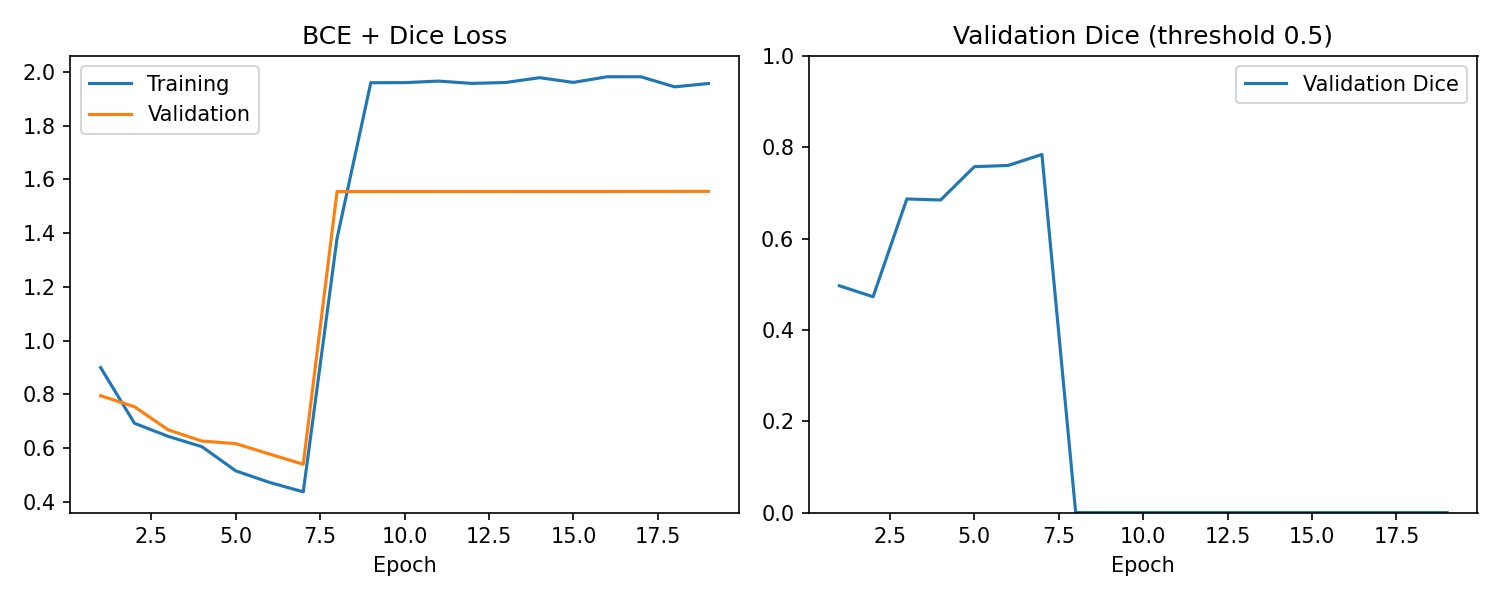

Full training curve: /content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/model_output/colab_runs/20261101_205443/training_history.png


In [12]:
from IPython.display import Image as DisplayImage, display

display(DisplayImage(filename=str(RUN_DIR / 'training_history.png')))
print('Full training curve:', RUN_DIR / 'training_history.png')

## Final unseen-test evaluation — exactly once per run

This cell creates an exclusive lock before invoking the existing evaluator. If evaluation fails or the runtime disconnects mid-evaluation, do not rerun it in this run folder; retain the partial artifacts for audit and start a fresh training run for a new evaluation. The report uses pixel-pooled confusion counts over the test slices (not a mean of per-slice or per-patient scores). The fixed probability threshold is 0.5 and is not tuned on test data.

In [13]:
evaluation_lock = RUN_DIR / 'final_test_evaluation_started.json'
if (RUN_DIR / 'test_metrics.json').exists() or evaluation_lock.exists():
    raise RuntimeError('Final test evaluation already started or completed for this run; refusing a second evaluation.')
with evaluation_lock.open('x', encoding='utf-8') as lock_file:
    json.dump({'status': 'started', 'checkpoint': str(checkpoint_path), 'started_at': datetime.now().isoformat()}, lock_file, indent=2)
evaluation_command = [
    sys.executable, str(PYTHON_DIR / 'evaluate_pytorch.py'),
    '--data-dir', str(DATA_DIR), '--output-dir', str(RUN_DIR),
    '--checkpoint', str(checkpoint_path), '--split-file', str(RUN_DIR / 'patient_split.json'),
    '--threshold', '0.5', '--batch-size', '4', '--num-examples', '6',
]
run_logged(evaluation_command, RUN_DIR / 'final_test_evaluation.log')
test_metrics = json.loads((RUN_DIR / 'test_metrics.json').read_text(encoding='utf-8'))
if test_metrics['evaluation'] != 'unseen patient-level test split only' or test_metrics['threshold_selected_using_test_data']:
    raise ValueError('Unexpected test evaluation protocol in metrics output.')
with evaluation_lock.open('w', encoding='utf-8') as lock_file:
    json.dump({'status': 'completed', 'checkpoint': str(checkpoint_path), 'completed_at': datetime.now().isoformat()}, lock_file, indent=2)
print(json.dumps(test_metrics, indent=2))
print('Metric aggregation: pixel-pooled TP/FP/FN across all test slices; no patient-level average is reported.')

  "checkpoint_epoch": 7,
  "checkpoint_validation_dice": 0.7843571159594795,
  "dataset_validation": {
    "pair_count": 3929,
    "patient_count": 110,
    "image_shapes": [
      [
        256,
        256,
        3
      ]
    ],
    "mask_shapes": [
      [
        256,
        256
      ]
    ],
    "mask_values": [
      0,
      255
    ]
  }
}
{
  "checkpoint_epoch": 7,
  "checkpoint_validation_dice": 0.7843571159594795,
  "dataset_validation": {
    "image_shapes": [
      [
        256,
        256,
        3
      ]
    ],
    "mask_shapes": [
      [
        256,
        256
      ]
    ],
    "mask_values": [
      0,
      255
    ],
    "pair_count": 3929,
    "patient_count": 110
  },
  "device": "cpu",
  "evaluation": "unseen patient-level test split only",
  "metrics": {
    "dice": 0.7816070845025157,
    "iou": 0.6415065900012856,
    "precision": 0.7721026275841646,
    "recall": 0.79134845439755
  },
  "pixel_counts": {
    "false_negative": 76307,
    "false_pos

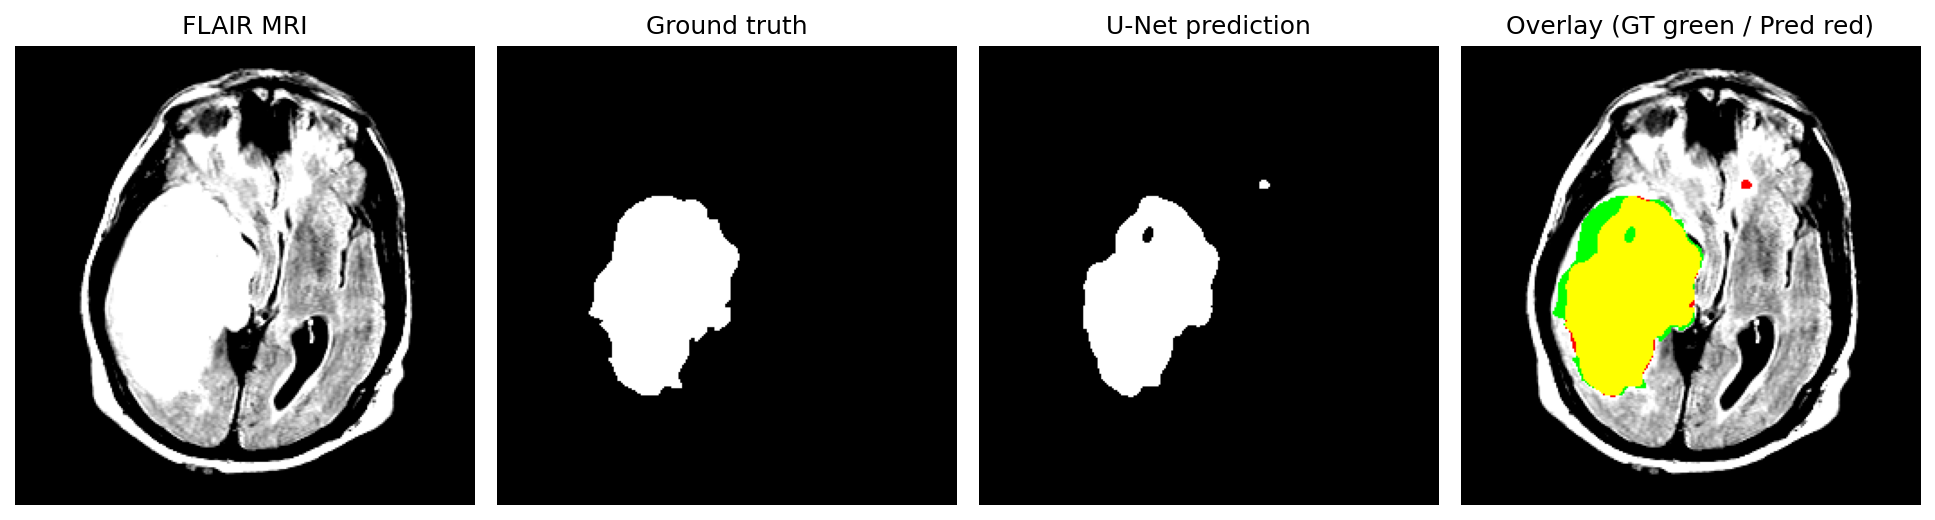

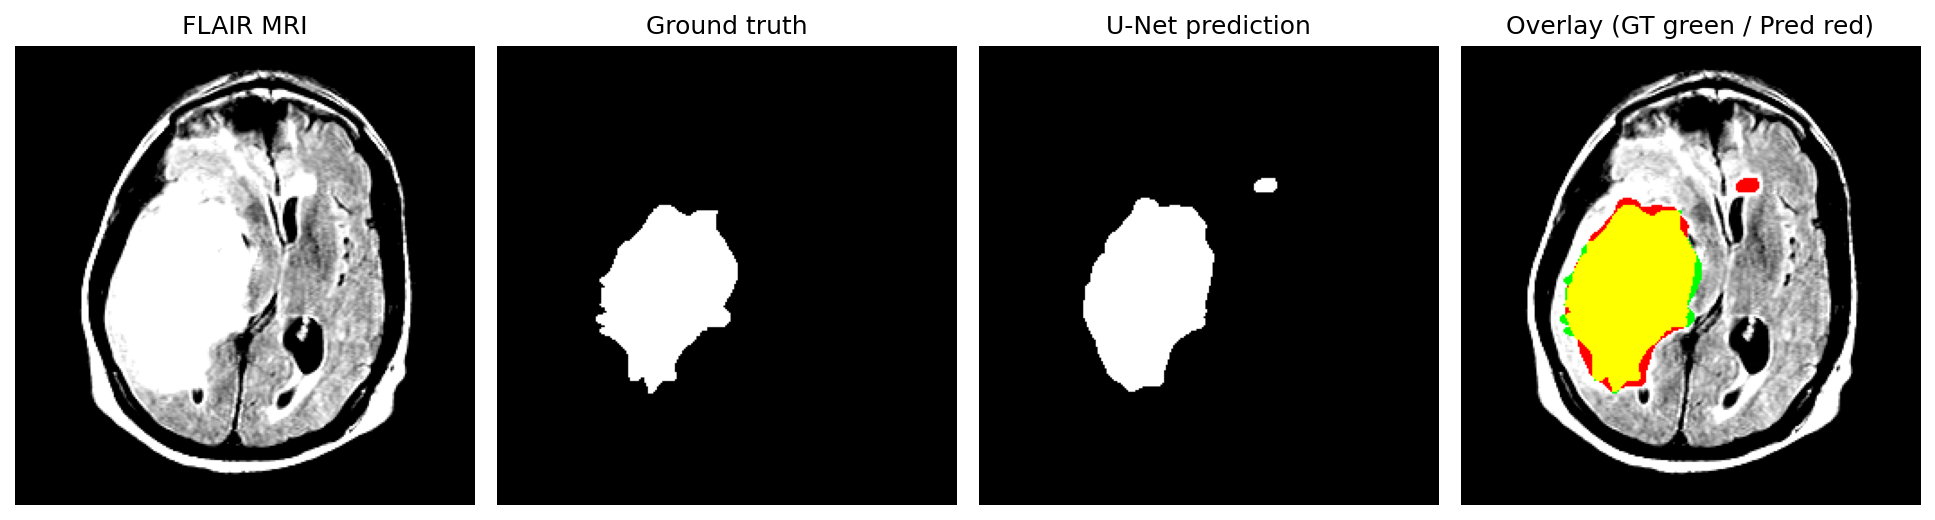

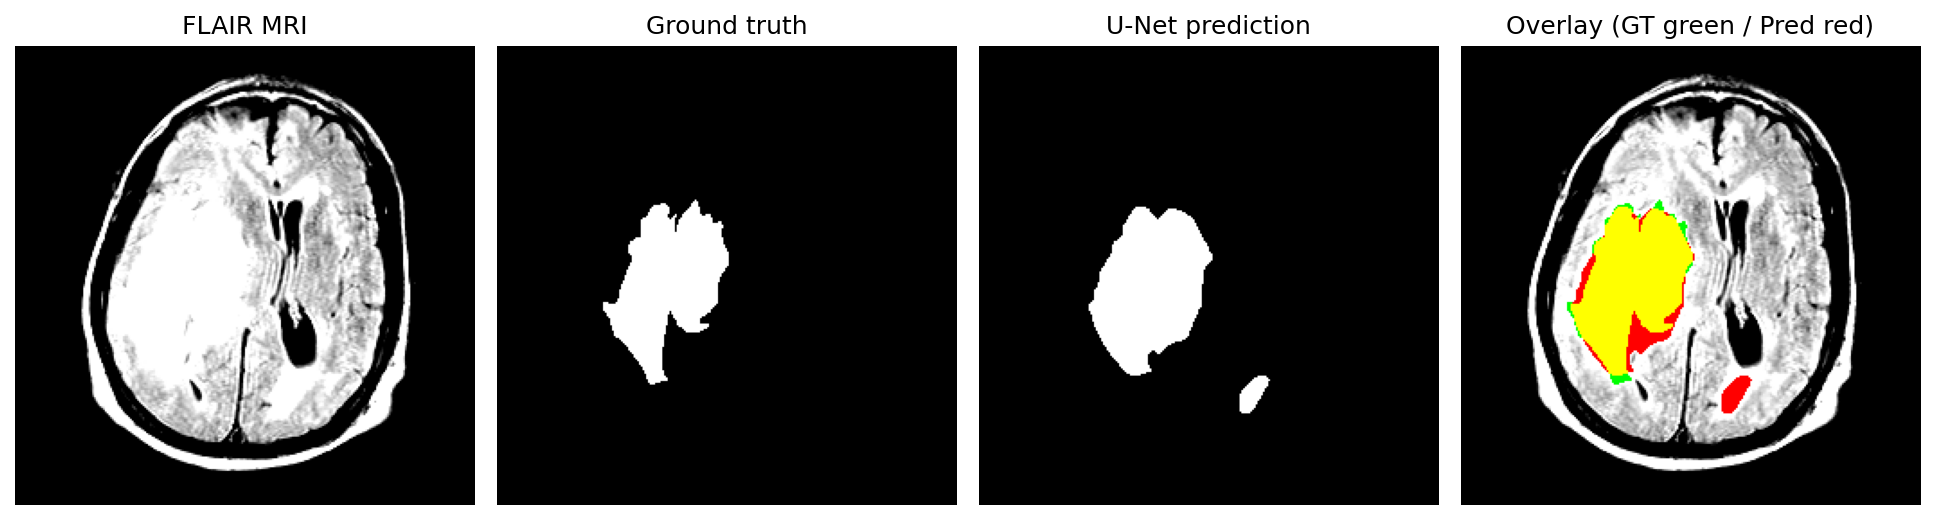

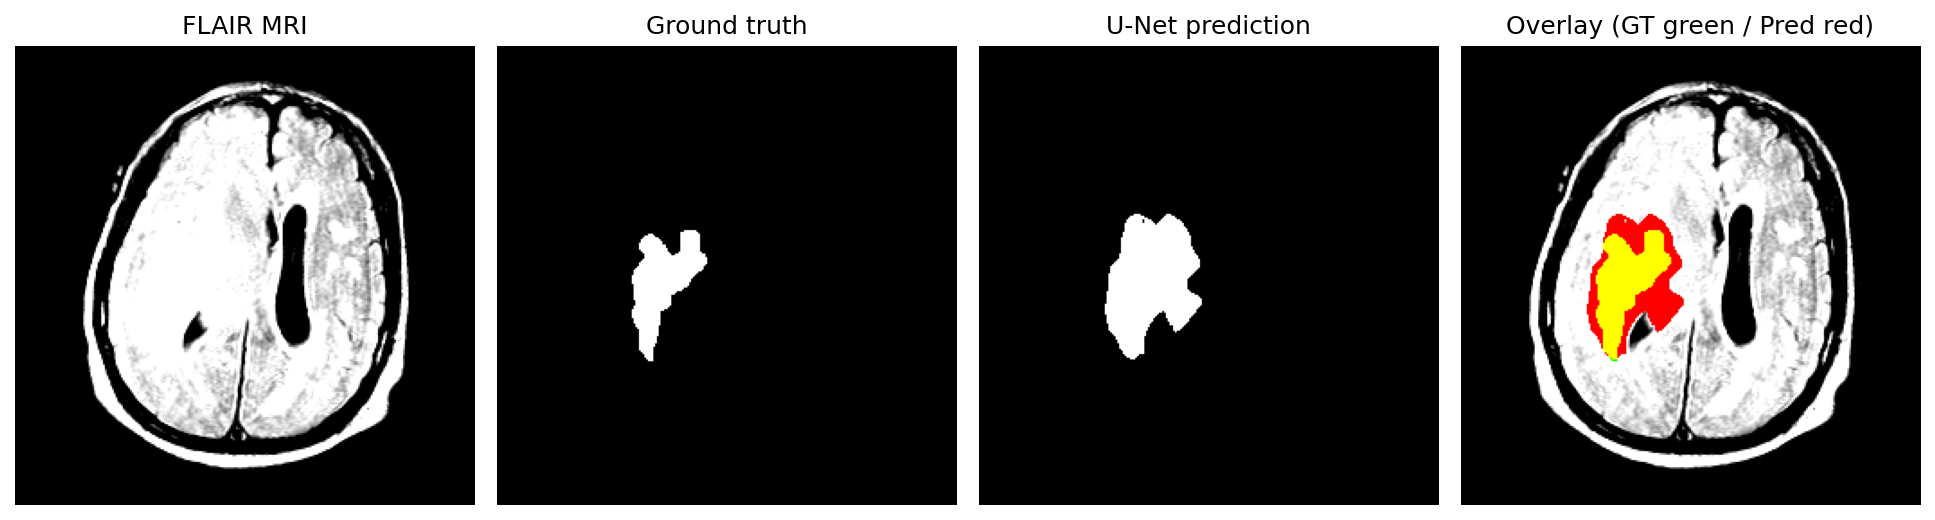

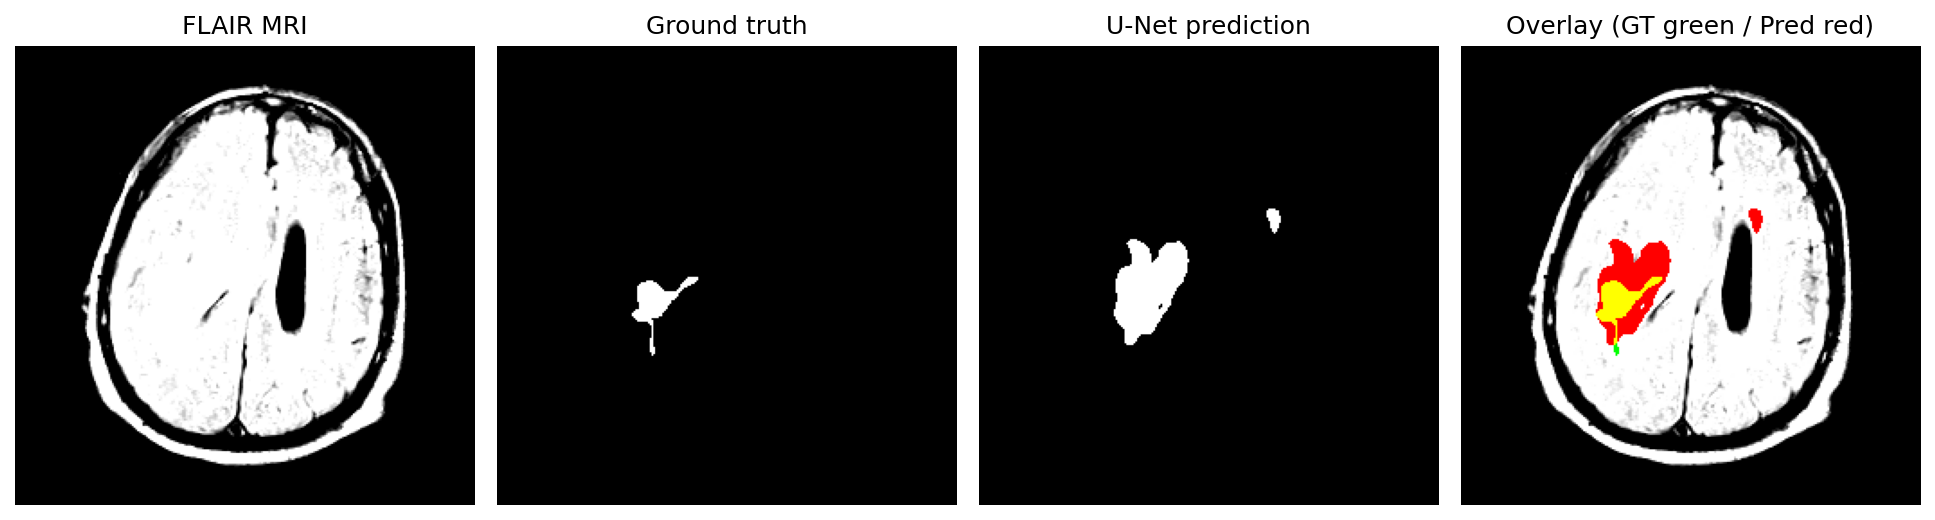

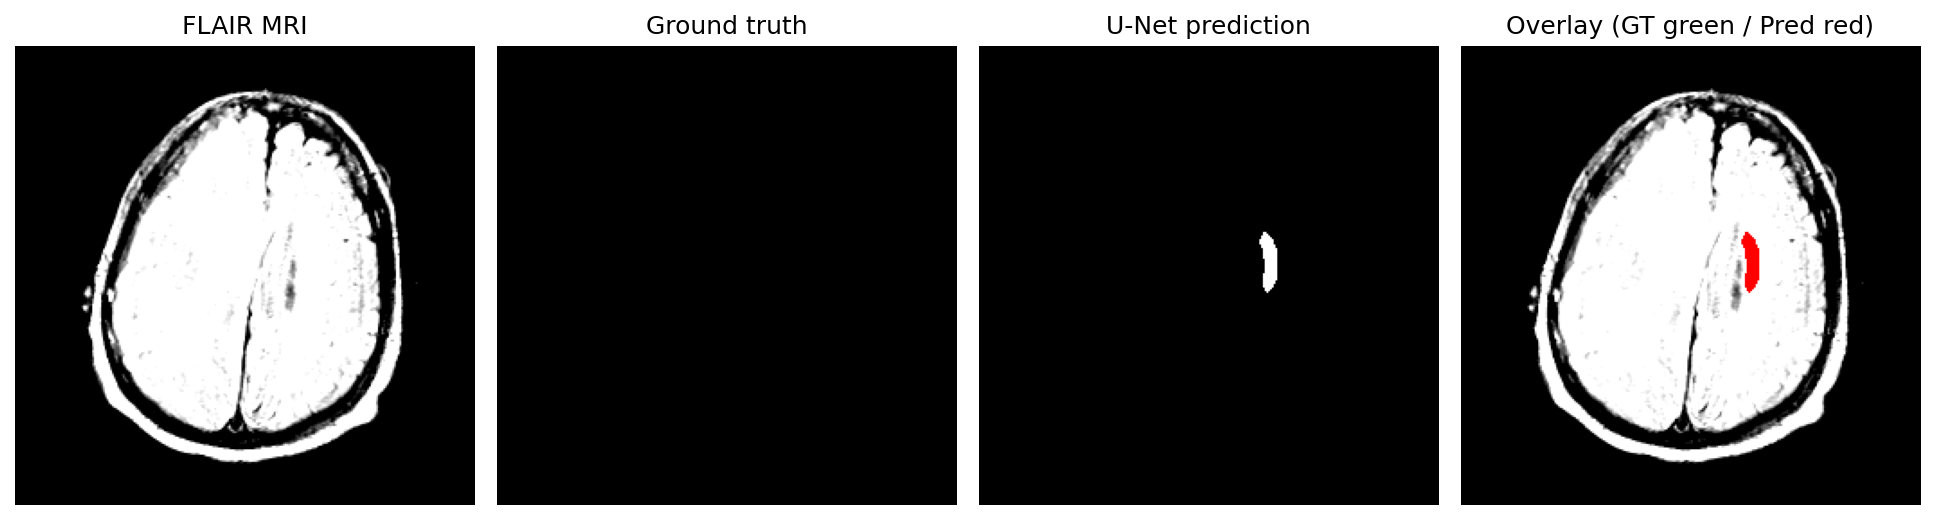

Unseen-test visualization count: 6


In [14]:
example_paths = sorted((RUN_DIR / 'test_examples').glob('*.png'))
for example_path in example_paths:
    display(DisplayImage(filename=str(example_path)))
print('Unseen-test visualization count:', len(example_paths))

## ONNX export and parity

Exports the validation-selected checkpoint and compares PyTorch and ONNX Runtime probabilities on fixed unseen-test samples. This is numerical parity verification, not a second metric evaluation. The exporter checks output dimensions, probability closeness, and exact thresholded-mask agreement.

In [15]:
subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '-q', 'onnx>=1.16', 'onnxruntime>=1.18'],
    check=True,
)
onnx_path = RUN_DIR / 'unet_model.onnx'
onnx_command = [
    sys.executable, str(PYTHON_DIR / 'export_pytorch_onnx.py'),
    '--checkpoint', str(checkpoint_path), '--data-dir', str(DATA_DIR),
    '--split-file', str(RUN_DIR / 'patient_split.json'), '--output', str(onnx_path),
    '--parity-report', str(RUN_DIR / 'onnx_parity.json'), '--samples', '5',
]
run_logged(onnx_command, RUN_DIR / 'onnx_export.log')
onnx_parity = json.loads((RUN_DIR / 'onnx_parity.json').read_text(encoding='utf-8'))
assert onnx_parity['allclose_passed'] is True
assert onnx_parity['thresholded_mask_parity_passed'] is True
assert onnx_parity['input_shape_nchw'] == [None, 1, 256, 256]
assert onnx_parity['output_shape_nchw'] == [None, 1, 256, 256]
print(json.dumps(onnx_parity, indent=2))

  "output_shape_nchw": [
    null,
    1,
    256,
    256
  ],
  "dtype": "tensor(float)",
  "providers": [
    "CPUExecutionProvider"
  ],
  "test_patients_used": [
    "TCGA_CS_4944_20010208"
  ],
  "samples_compared": 5,
  "atol": 1e-05,
  "rtol": 0.0001,
  "max_absolute_error": 3.2782554626464844e-07,
  "max_relative_error": 1.1467328071594238,
  "allclose_passed": true,
  "probability_threshold": 0.5,
  "thresholded_mask_mismatch_pixels": 0,
  "thresholded_mask_parity_passed": true,
  "note": "Parity check uses unseen test inputs only; no metrics or threshold were tuned."
}
{
  "allclose_passed": true,
  "atol": 1e-05,
  "checkpoint": "/content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/model_output/colab_runs/20261101_205443/best_unet.pth",
  "dtype": "tensor(float)",
  "input_name": "flair",
  "input_shape_nchw": [
    null,
    1,
    256,
    256
  ],
  "max_absolute_error": 3.2782554626464844e-07,
  "max_relative_error": 1.1467328071594238,
  "note": "Parity chec

## Persisted deliverables and download

All outputs are in `RUN_DIR` on mounted Google Drive. The ONNX model, checkpoint, test metrics, training history/curve, split, model and normalization configs, ONNX parity report, six visual examples, and `MATLAB_Export/` predictions are persisted there. Use the printed absolute Drive path to download files via Google Drive or package the run folder into a ZIP (excluding logs if desired).

In [16]:
required_files = [
    'best_unet.pth', 'unet_model.onnx', 'test_metrics.json', 'colab_environment.json',
    'training_history.json', 'training_history.png', 'patient_split.json',
    'model_config.json', 'normalization_config.json', 'onnx_parity.json',
]
missing_files = [name for name in required_files if not (RUN_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Incomplete run artifacts: {missing_files}')
for name in required_files:
    print(f'{name}: {(RUN_DIR / name).stat().st_size:,} bytes')
print('Drive run folder:', RUN_DIR)
print('Representative predictions:', RUN_DIR / 'test_examples')
print('MATLAB export:', RUN_DIR / 'MATLAB_Export')
print('To download: open the run folder in Google Drive, right-click it, and choose Download (Drive creates a ZIP); individual files can also be downloaded directly.')

best_unet.pth: 124,140,929 bytes
unet_model.onnx: 124,134,029 bytes
test_metrics.json: 815 bytes
colab_environment.json: 264 bytes
training_history.json: 4,139 bytes
training_history.png: 64,175 bytes
patient_split.json: 7,753 bytes
model_config.json: 676 bytes
normalization_config.json: 569 bytes
onnx_parity.json: 984 bytes
Drive run folder: /content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/model_output/colab_runs/20261101_205443
Representative predictions: /content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/model_output/colab_runs/20261101_205443/test_examples
MATLAB export: /content/drive/MyDrive/MedicalImageAnalysis_Colab_Docker_MATLAB/model_output/colab_runs/20261101_205443/MATLAB_Export
To download: open the run folder in Google Drive, right-click it, and choose Download (Drive creates a ZIP); individual files can also be downloaded directly.
